In [2]:
# Install Qiskit + the simulator + plotting (safe to re-run)
!pip install qiskit qiskit-aer pylatexenc matplotlib numpy --quiet

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram, plot_bloch_multivector
import matplotlib.pyplot as plt
import numpy as np

sim = AerSimulator()   # a pretend quantum computer inside this notebook

def run(circuit, shots=1024):
    """Run a circuit many times and count the outcomes."""
    return sim.run(transpile(circuit, sim), shots=shots).result().get_counts()

print("✅ Qiskit is ready. On to the quantum stuff!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 72.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 94.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 92.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.1 MB/s eta 0:00:00
✅ Qiskit is ready. On to the quantum stuff!


In [ ]:
# MODULE 01

{'11': 9907, '01': 10093}


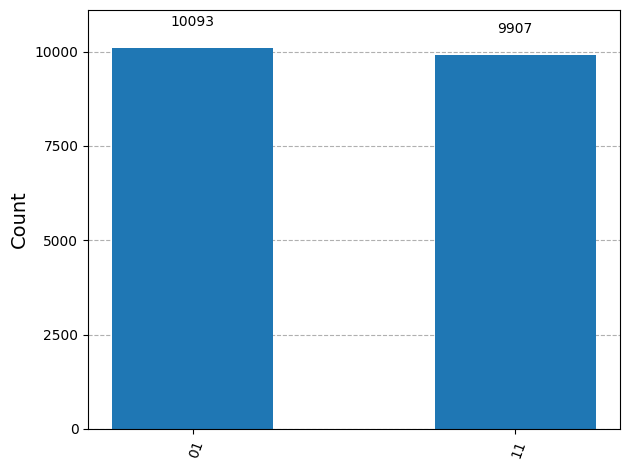

In [6]:
#Produce a bit that is always 1, and a bit that is perfectly uncertain (50/50) over many shots).
qc = QuantumCircuit(2, 2)   # 2 qubit, 2 classical bit
qc.x(0)
qc.h(1)
qc.measure(0,0)
qc.measure(1,1)
counts = run(qc, shots=20000)
print(counts)
plot_histogram(counts)

{'0': 20000}


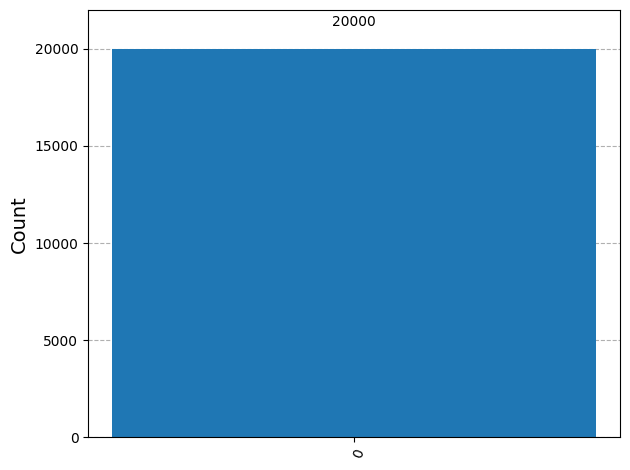

In [7]:
#Produce a bit that looks uncertain but is secretly certain — a two-gate sequence whose result is always the same. Explain why it happens
qc = QuantumCircuit(1, 1)
qc.h(0)
qc.h(0)
qc.measure(0,0)
qc.draw()
counts = run(qc, shots=20000)
print(counts)
plot_histogram(counts)

In [12]:
#The vault wants the exact 3-bit pattern 101, built from 000. Produce it, measured.
qc = QuantumCircuit(3, 3)
qc.x(0)
qc.x(2)
qc.measure([0,1,2],[0,1,2])
print("Counts:", run(qc, shots=100))

Counts: {'101': 100}


In [ ]:
# MODULE 2

In [14]:
#Bronze. Build a genuine quantum coin and show it's fair — ≈50/50 over ~1000 shots.
def quantum_coin(shots=1000):
    # Simulate a fair quantum coin using a Hadamard gate.
    qc = QuantumCircuit(1, 1)
    qc.h(0)
    qc.measure(0, 0)

    counts = run(qc, shots=shots)
    probabilities = {bit: count / shots for bit, count in counts.items()}
    return counts, probabilities

coin_counts, coin_probabilities = quantum_coin(shots=1000)
print("Counts:", coin_counts)
print("Estimated probabilities:", coin_probabilities)

Counts: {'0': 517, '1': 483}
Estimated probabilities: {'0': 0.517, '1': 0.483}


In [20]:
#Run the seed circuit we left in the notebook. It looks random. Is it? Measure it,and tell us the truth
# the recovered seed circuit — run it as-is
seed = QuantumCircuit(1, 1)
seed.ry(1.159, 0)
seed.measure(0, 0)
print(run(seed))

{'1': 305, '0': 719}


In [21]:
# Put a number on any bias, and say how many shots you'd need to be sure it isn't just a fair coin having an unlucky day.

#Since bias is considerable (0.20) , we only need 56 shots to be sure of the biaseness of coin.
seed = QuantumCircuit(1, 1)
seed.ry(1.159, 0)
seed.measure(0, 0)
print(run(seed, shots=56))


{'1': 11, '0': 45}


In [ ]:
#MODULE 3

{'11': 507, '00': 517}


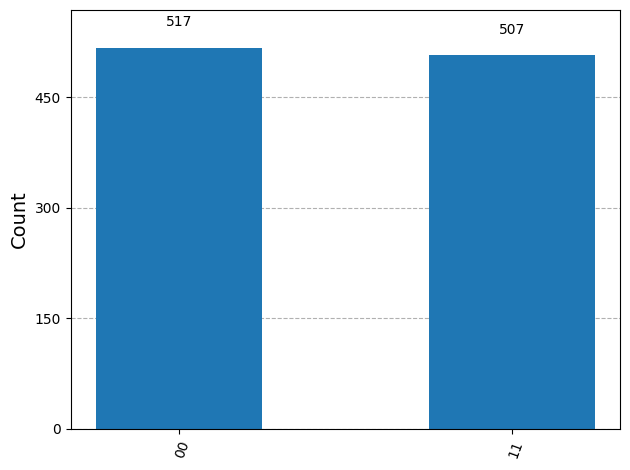

In [23]:
#Build the pair that only ever agrees — outcomes 00 and 11, never 01/10. Show it.
qc = QuantumCircuit(2, 2)
qc.h(0)                  # superposition on qubit 0
qc.cx(0, 1)              # CNOT: entangle qubit 0 (control) with qubit 1 (target)
qc.measure([0, 1], [0, 1])
counts = run(qc, shots=1024)
print(counts)            # -> only '00' and '11'
plot_histogram(counts)

In [25]:
import random
from collections import Counter

In [ ]:
#Show that two people who agreed on a secret coin-flip beforehand would also always agree. So does "always agreeing" actually prove a quantum link? Make your case

{'00': 47, '11': 53}


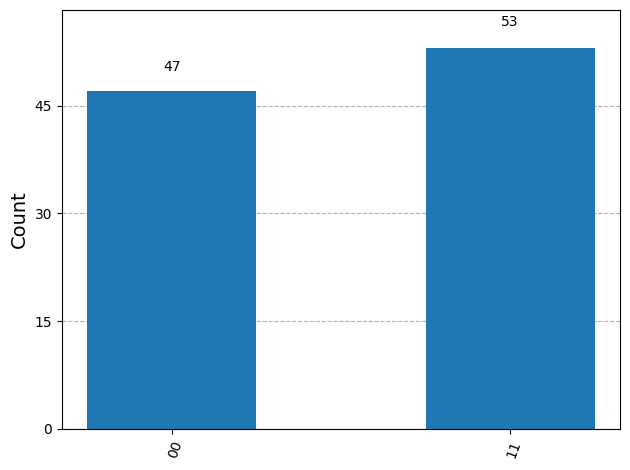

In [28]:
counts = Counter()
for _ in range(100):
    secret = random.randint(0, 1)      # the pre-agreed coin flip
    qc = QuantumCircuit(2, 2)
    if secret:
        qc.x(0); qc.x(1)               # both detectors get the same value
    qc.measure([0,1],[0,1])
    counts.update(run(qc, shots=1))

print(dict(counts))   # about {'00': 500, '11': 500}, never 01 or 10
plot_histogram(dict(counts))

In [ ]:
#Find an experiment that tells these two apart — something the real quantum pair does that a pre-agreed secret simply can't. (You don't have to measure the same way every time.)


{'00': 68, '01': 9, '10': 12, '11': 11}


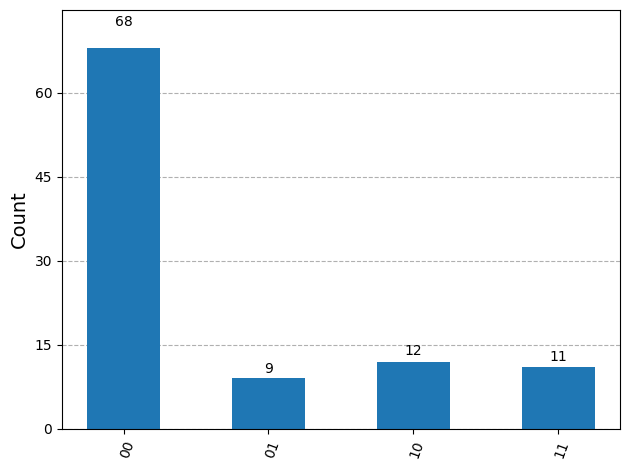

In [29]:
counts = Counter()
for _ in range(100):
    secret = random.randint(0, 1)      # the pre-agreed coin flip
    qc = QuantumCircuit(2, 2)
    if secret:
        qc.x(0); qc.x(1)
        qc.h(0); qc.h(1)              # adding hamadard gate on bits exposes the fake one
    qc.measure([0,1],[0,1])
    counts.update(run(qc, shots=1))

print(dict(counts))   # about {'00': 500, '11': 500}, never 01 or 10
plot_histogram(dict(counts))

{'00': 506, '11': 518}


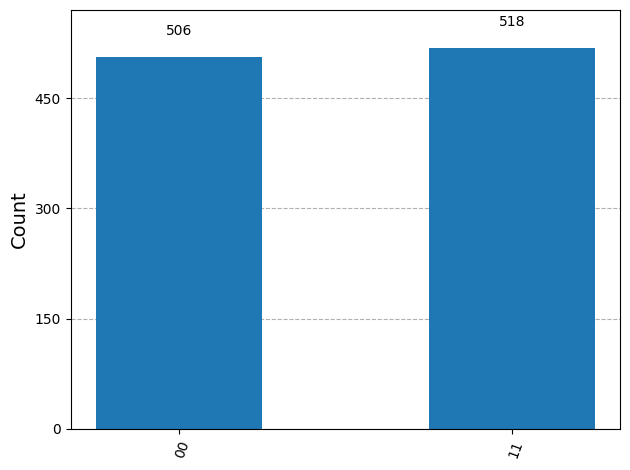

In [30]:
qc = QuantumCircuit(2, 2)
qc.h(0)                  # superposition on qubit 0
qc.cx(0, 1)              # CNOT: entangle qubit 0 (control) with qubit 1 (target)
qc.h(0), qc.h(1)         # REAL QUANTUM COIN WONT DISSAPPOINT you
qc.measure([0, 1], [0, 1])
counts = run(qc, shots=1024)
print(counts)            # -> only '00' and '11'
plot_histogram(counts)

In [ ]:
# MODULE 4

# Show one sequence where the state is recoverable, and one where measuring destroys it for good. What's the difference?

{'0': 1024}


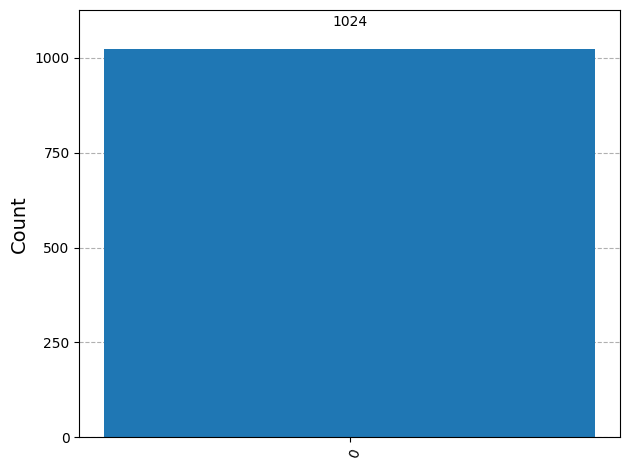

In [35]:
# SEQUENCE WHICH IS RECOVERABLE
qc = QuantumCircuit(1,1)
qc.h(0)
qc.h(0)
qc.measure(0,0)
counts = run(qc, shots=1000)
print(counts)
plot_histogram(counts)


{'1': 512, '0': 488}


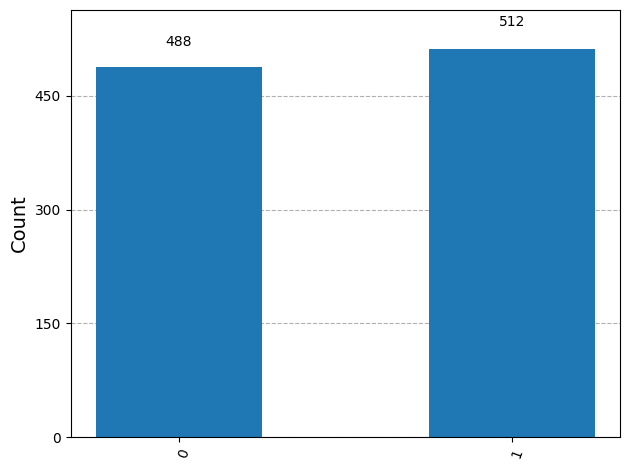

In [36]:
# SEQUENCE WHICH IS NOT RECOVERABLE
qc = QuantumCircuit(1,1)
qc.h(0)
qc.measure(0,0)
qc.h(0)
qc.measure(0,0)
counts = run(qc, shots=1000)
print(counts)
plot_histogram(counts)

In [38]:
# Predict first, then run: what does X then H then H give? What about H then X then H? Explain what's really doing the "erasing."

# PREDICTION OF X THEN H THEN H ALWAYS GIVES 1 AS H AND H CANCELS EACH OTHER OUT

# PREDICTION OF H THEN X THEN H ALWAYS GIVES 0 as x part ONLY REVERSE BUT ORDER DOESNT MATTER SO ITS SAME BUT SECOND H CANCELS OUT 1 AND LEAVES 0

a = QuantumCircuit(1,1); a.x(0); a.h(0); a.h(0); a.measure(0,0)
b = QuantumCircuit(1,1); b.h(0); b.x(0); b.h(0); b.measure(0,0)
print(run(a,shots=1000))
print(run(b,shots=1000))

{'1': 1000}
{'0': 1000}


In [ ]:
### Module 05 — The Damaged Message

In [42]:
#Recover the original message. (If you see each bit three times, which value do you trust?)

# RULE IS TO TRUST THE MAJORITY, IF TWO OUT OF 3 BITS ARE SAME TRUST THEM.
stream = "100011001001001011100110001011000000001100011011000111000000110000001000000111001010101011111111"
corrected = []

for i in range(0, len(stream), 3):
    chunk = stream[i:i+3]
    if len(chunk) < 3: break

    b1, b2, b3 = chunk[0], chunk[1], chunk[2]

    if b1 == b2:         b3 = b1
    elif b1 == b3:       b2 = b1
    elif b2 == b3:       b1 = b2

    corrected.append([b1, b2, b3])

print(corrected)



[['0', '0', '0'], ['1', '1', '1'], ['0', '0', '0'], ['0', '0', '0'], ['0', '0', '0'], ['1', '1', '1'], ['0', '0', '0'], ['1', '1', '1'], ['0', '0', '0'], ['1', '1', '1'], ['0', '0', '0'], ['0', '0', '0'], ['0', '0', '0'], ['0', '0', '0'], ['1', '1', '1'], ['1', '1', '1'], ['0', '0', '0'], ['1', '1', '1'], ['0', '0', '0'], ['0', '0', '0'], ['1', '1', '1'], ['0', '0', '0'], ['0', '0', '0'], ['0', '0', '0'], ['0', '0', '0'], ['1', '1', '1'], ['0', '0', '0'], ['0', '0', '0'], ['1', '1', '1'], ['1', '1', '1'], ['1', '1', '1'], ['1', '1', '1']]


In [46]:
#Show a case where this trick fails — where the corruption is bad enough that majority vote gives the wrong answer. Point to exactly where it breaks.

##### THIS RULE FAILS IF MAJORITY BITS ARE FLIPPED, IN OUR CASE 2
message_chunk = [1,1,0]
output = []
b1, b2, b3 = message_chunk[0], message_chunk[1], message_chunk[2]
if b1 == b2:         b3 = b1
elif b1 == b3:       b2 = b1
elif b2 == b3:       b1 = b2

output.append([b1, b2, b3])

print(output)


[[1, 1, 1]]


In [ ]:
#IN ABOVE CODE WE SAW AS EVEN IF ORIGINAL MESSAGE WAS OF FALSE (0), WE ENDED UP INTERPRETING IT AS TRUE (1) DUE TO MAJORITY RULE

In [ ]:
# How many flips can this scheme correct vs just notice? And why can't you protect a real qubit by simply copying it three times?

# IT CAN CORRECT 1 FLIP AND CAN NOTICE 2 FLIPS
# WE CAN NOT PROTECT A QUANTUM BIT BY SIMPLY COPYING IT BECAUSE OF NON-CLONING THEOREM AND ALSO BECAUSE MEASURING TO COMPARE DESTROYS IT

